# Mini-Project 3: Lake Victoria Fish Stock & Export Risk Model

**Question.** A fish-export cooperative in Jinja asks: (a) is its harvesting rate sustainable, and (b) how risky is its revenue?

**Approach.** Replace the old Fibonacci stock model with a discrete logistic model with harvesting, add a seeded random-walk price, and measure risk with a unit-free coefficient of variation (CV) and a Monte Carlo Value-at-Risk (VaR).

**Reusable code** lives in `src/fish_model.py` (`FishStock`, `PriceModel`, `RiskAssessor`, `run_scenario`). Tests are in `tests/test_project3.py`.

**Units.** Stock and harvest in tonnes, price in UGX/kg, revenue in UGX. One time step = 1 week, so `r` and `h` are per-week rates.

**Key assumptions** (all illustrative, stated up front):
1. Harvest each week is `h * N(t)` tonnes (effort-proportional fishing), taken from the stock at the start of the week.
2. Price is independent of stock and of the cooperative's catch (price-taker).
3. Stock dynamics are deterministic; only price is random.
4. Fixed seed everywhere, so *Restart & Run All* gives identical results.

In [1]:
import statistics

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.fish_model import (FishStock, PriceModel, RiskAssessor,
    closed_season_mask, describe, fibonacci, run_scenario, weekly_revenue,)

SEED = 2026
R, K, N0, WEEKS = 0.4, 10_000, 4_000, 52
H_SCENARIOS = [0.05, 0.10, 0.20, 0.30]
N_PATHS = 5_000          # Monte Carlo price paths (task requires >= 1,000)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.options.display.float_format = "{:,.2f}".format

## Task 1. Baseline: Fibonacci "stock"

The previous cohort treated the first 15 Fibonacci numbers as a fish stock. Below: the numbers, their growth ratios, and how long until they exceed the lake's carrying capacity.

First 15 terms: [1, 1, 2, 3, 5, 8, 13, 21, 34, 55, 89, 144, 233, 377, 610]
Ratio F(n+1)/F(n) -> 1.6180  (golden ratio = 1.6180)
Fibonacci 'stock' passes K = 10,000 t at term 21, and keeps growing forever.


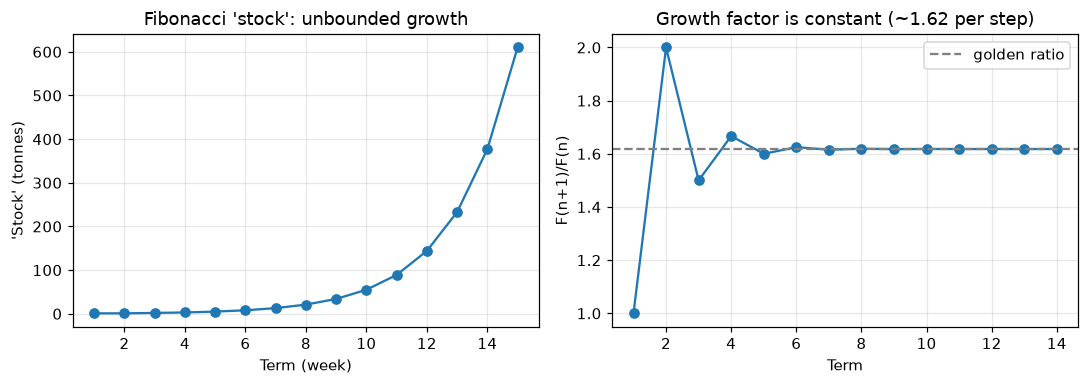

In [2]:
fib = fibonacci(15)
ratios = [b / a for a, b in zip(fib, fib[1:])]
first_over_K = next(i + 1 for i, v in enumerate(fibonacci(40)) if v > K)
print("First 15 terms:", fib)
print(f"Ratio F(n+1)/F(n) -> {ratios[-1]:.4f}  (golden ratio = {(1 + 5 ** 0.5) / 2:.4f})")
print(f"Fibonacci 'stock' passes K = {K:,} t at term {first_over_K}, and keeps growing forever.")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(range(1, 16), fib, "o-")
ax[0].set(title="Fibonacci 'stock': unbounded growth", xlabel="Term (week)", ylabel="'Stock' (tonnes)")
ax[1].plot(range(1, 15), ratios, "o-")
ax[1].axhline((1 + 5 ** 0.5) / 2, ls="--", c="grey", label="golden ratio")
ax[1].set(title="Growth factor is constant (~1.62 per step)", xlabel="Term", ylabel="F(n+1)/F(n)")
ax[1].legend()
plt.tight_layout(); plt.show()

**Why Fibonacci growth is biologically unrealistic.** Each term is the sum of the previous two, so the stock multiplies by about 1.62 every step with no ceiling. A lake has finite food, oxygen and habitat, so real stocks slow down as they approach a carrying capacity *K* and stabilise near it. Fibonacci numbers also have no link to a growth rate, no harvesting term and no way to decline, so the model cannot say anything about sustainability. Its only appeal is that it is easy to generate, not that it describes fish.

## Task 2. `FishStock`: discrete logistic growth with harvesting

$$N_{t+1} = N_t + rN_t\left(1-\frac{N_t}{K}\right) - hN_t$$

Theory gives two checks for the simulation:
- Non-trivial equilibrium: $N^* = K(1 - h/r)$ (zero if $h \ge r$, i.e. collapse).
- Equilibrium yield $hN^*$ is maximised at $h = r/2$, giving $\text{MSY} = rK/4$.

FishStock(r=0.4, K=10,000 t, n0=4,000 t)
Theoretical MSY = rK/4 = 1,000 t/week, reached at h = r/2 = 0.20


,h,closed-form N*,simulated N (500 wk)
0,0.05,"8,750.00","8,750.00"
1,0.10,"7,500.00","7,500.00"
2,0.20,"5,000.00","5,000.00"
3,0.30,"2,500.00","2,500.00"


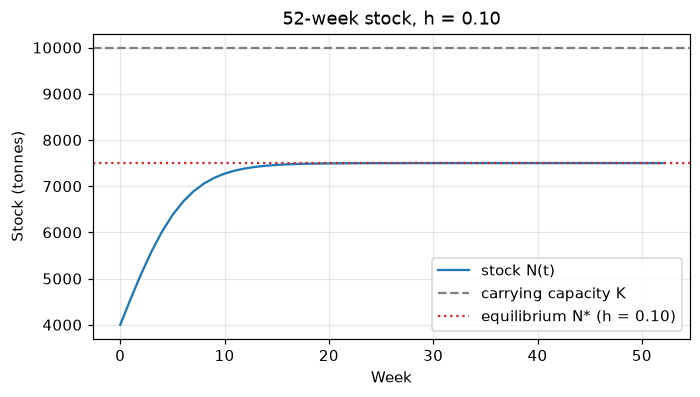

In [3]:
fish = FishStock(r=R, K=K, n0=N0)
print(fish)
print(f"Theoretical MSY = rK/4 = {fish.msy:,.0f} t/week, reached at h = r/2 = {fish.h_msy:.2f}")

# Validation by a second method: a long run must converge to the closed-form equilibrium
check = pd.DataFrame({
    "h": H_SCENARIOS,
    "closed-form N*": [fish.equilibrium(h) for h in H_SCENARIOS],
    "simulated N (500 wk)": [fish.simulate(500, h)[0][-1] for h in H_SCENARIOS],
})
display(check)

stock, harvest = fish.simulate(WEEKS, h=0.10)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(stock, label="stock N(t)")
ax.axhline(K, ls="--", c="grey", label="carrying capacity K")
ax.axhline(fish.equilibrium(0.10), ls=":", c="C3", label="equilibrium N* (h = 0.10)")
ax.set(title="52-week stock, h = 0.10", xlabel="Week", ylabel="Stock (tonnes)")
ax.legend(); plt.show()

## Task 3. `PriceModel`: seeded bounded random walk

Price starts at UGX 12,000/kg, moves by a Normal(0, 350) step each week (about 3% of the price) and is clipped to the UGX 9,000-16,000 band. Weekly revenue = harvest (kg) × price (UGX/kg).

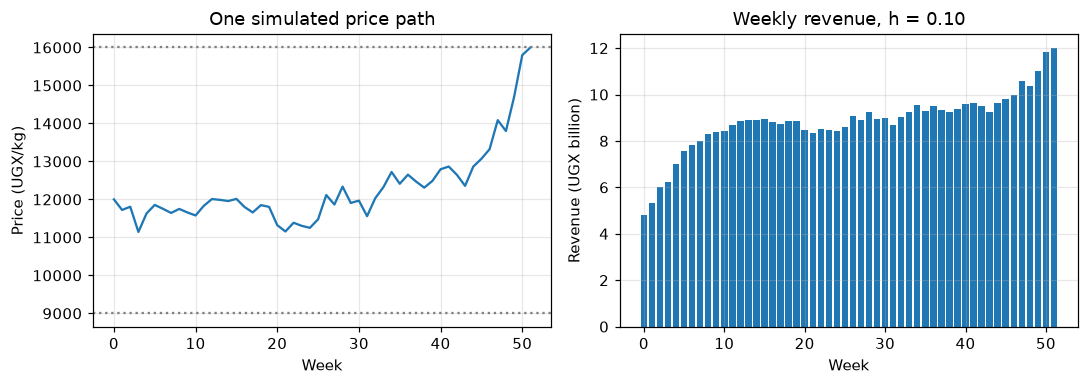

In [4]:
price_path = PriceModel(seed=SEED).simulate(weeks=WEEKS, n_paths=1)[0]
revenue_wk = weekly_revenue(harvest, price_path)          # UGX, h = 0.10

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(price_path)
ax[0].axhline(9_000, ls=":", c="grey"); ax[0].axhline(16_000, ls=":", c="grey")
ax[0].set(title="One simulated price path", xlabel="Week", ylabel="Price (UGX/kg)")
ax[1].bar(range(WEEKS), revenue_wk / 1e9)
ax[1].set(title="Weekly revenue, h = 0.10", xlabel="Week", ylabel="Revenue (UGX billion)")
plt.tight_layout(); plt.show()

## Task 4. Descriptive statistics and the CV

All statistics use the `statistics` module (sample variance, `n-1`).

In [5]:
s = describe(revenue_wk)
print(f"mean     = UGX {s['mean']:,.0f}")
print(f"median   = UGX {s['median']:,.0f}")
print(f"variance = {s['variance']:.3e} UGX^2")
print(f"std dev  = UGX {s['std']:,.0f}")
print(f"CV       = {s['cv']:.3f}  (unit-free)")

# Why a raw variance threshold of 50,000 is meaningless: variance changes with the unit.
rev_bn = [v / 1e9 for v in revenue_wk]
print()
print("Same data, different units:")
print(f"  variance in UGX^2          = {statistics.variance(revenue_wk):.3e}  > 50,000 ? {statistics.variance(revenue_wk) > 50_000}")
print(f"  variance in (UGX billion)^2 = {statistics.variance(rev_bn):.3f}  > 50,000 ? {statistics.variance(rev_bn) > 50_000}")
print(f"  CV (either unit)            = {statistics.stdev(rev_bn) / statistics.mean(rev_bn):.3f}")

mean     = UGX 8,843,840,541
median   = UGX 8,898,951,354
variance = 1.721e+18 UGX^2
std dev  = UGX 1,311,859,490
CV       = 0.148  (unit-free)

Same data, different units:
  variance in UGX^2          = 1.721e+18  > 50,000 ? True
  variance in (UGX billion)^2 = 1.721  > 50,000 ? False
  CV (either unit)            = 0.148


**Why a variance threshold of 50,000 is meaningless.** Variance has units of the data squared (UGX²). Revenue here is in billions of shillings, so the variance is around 10¹⁸ UGX² and exceeds 50,000 by many orders of magnitude, meaning the old rule would flag *every* scenario as risky. Re-express the same revenue in UGX billions and the variance falls below 50,000, so the rule would call it safe. A rule whose verdict flips with the choice of unit cannot measure risk. The CV (standard deviation ÷ mean) is unit-free and measures volatility relative to the typical revenue, so it can be compared across scenarios and currencies.

## Task 5. `RiskAssessor`: CV rule and Monte Carlo VaR

**Rule (applied to the CV of simulated annual revenue across price paths):**

| CV | Class | Reason |
|---|---|---|
| < 0.15 | Low | annual revenue typically within about ±15% of its mean |
| 0.15 to < 0.30 | Medium | swings large enough to strain budgeting and loan repayments |
| ≥ 0.30 | High | a one-standard-deviation bad year costs ~30% or more of expected revenue |

These cut-offs are conventional rules of thumb, not laws; they are parameters of `RiskAssessor` and can be changed. I classify on the *annual-revenue CV across price paths* because that isolates price risk. The CV of weekly revenue within one path (Task 4) also contains the deterministic rise of the stock, which is a trend, not risk.

**VaR (5%)** is the 5th percentile of simulated annual revenue: the cooperative earns at least this much in 95% of simulated years. I also report the shortfall relative to the mean.

I use h = 0.20 here (the harvest rate at MSY); Task 6 repeats the analysis for all rates.

In [6]:
assessor = RiskAssessor(low_cut=0.15, high_cut=0.30)
H_FOCUS = 0.20
focus = run_scenario(fish, H_FOCUS, PriceModel(seed=SEED + 1), assessor, WEEKS, N_PATHS)

print(f"h = {H_FOCUS}, {N_PATHS:,} price paths")
print(f"  mean annual revenue : UGX {focus['mean'] / 1e9:,.1f} bn")
print(f"  CV of annual revenue: {focus['cv']:.3f}  -> risk class: {focus['risk']}")
print(f"  5% VaR (5th pct)    : UGX {focus['var_quantile'] / 1e9:,.1f} bn")
print(f"  shortfall vs mean   : UGX {focus['shortfall_vs_mean'] / 1e9:,.1f} bn")

h = 0.2, 5,000 price paths
  mean annual revenue : UGX 613.4 bn
  CV of annual revenue: 0.106  -> risk class: Low
  5% VaR (5th pct)    : UGX 513.8 bn
  shortfall vs mean   : UGX 99.5 bn


## Task 6. Scenario analysis and comparison with MSY

For each harvest rate: final stock, total (expected) annual revenue, risk class, VaR, and first-year harvest compared with the theoretical annual MSY (52 × rK/4 = 52,000 t).

In [7]:
rows = []
results = {}
for h in H_SCENARIOS:
    res = run_scenario(fish, h, PriceModel(seed=SEED + 1), assessor, WEEKS, N_PATHS)
    results[h] = res
    annual_msy = 52 * fish.msy
    status = ("below h_MSY (under-harvesting)" if h < fish.h_msy
              else "at h_MSY" if np.isclose(h, fish.h_msy)
              else "above h_MSY (overfishing)")
    rows.append({
        "h": h,
        "final stock (t)": res["stock"][-1],
        "equilibrium N* (t)": fish.equilibrium(h),
        "harvest yr 1 (t)": res["harvest"].sum(),
        "% of annual MSY": 100 * res["harvest"].sum() / annual_msy,
        "mean revenue (UGX bn)": res["mean"] / 1e9,
        "CV": res["cv"],
        "risk": res["risk"],
        "VaR 5% (UGX bn)": res["var_quantile"] / 1e9,
        "status": status,
    })
scen = pd.DataFrame(rows).set_index("h")
display(scen)
print(f"Annual MSY = 52 x rK/4 = {52 * fish.msy:,.0f} t, attained in equilibrium at h = {fish.h_msy:.2f}")

,final stock (t),equilibrium N* (t),harvest yr 1 (t),% of annual MSY,mean revenue (UGX bn),CV,risk,VaR 5% (UGX bn),status
h,,,,,,,,,
0.05,"8,750.00","8,750.00","21,714.61",41.76,261.85,0.11,Low,218.47,below h_MSY (under-harvesting)
0.10,"7,500.00","7,500.00","37,362.51",71.85,450.53,0.11,Low,376.16,below h_MSY (under-harvesting)
0.20,"4,999.99","5,000.00","50,871.71",97.83,613.36,0.11,Low,513.83,at h_MSY
0.30,"2,503.72","2,500.00","42,461.02",81.66,511.75,0.10,Low,433.52,above h_MSY (overfishing)


Annual MSY = 52 x rK/4 = 52,000 t, attained in equilibrium at h = 0.20


## Task 7. Visualisation

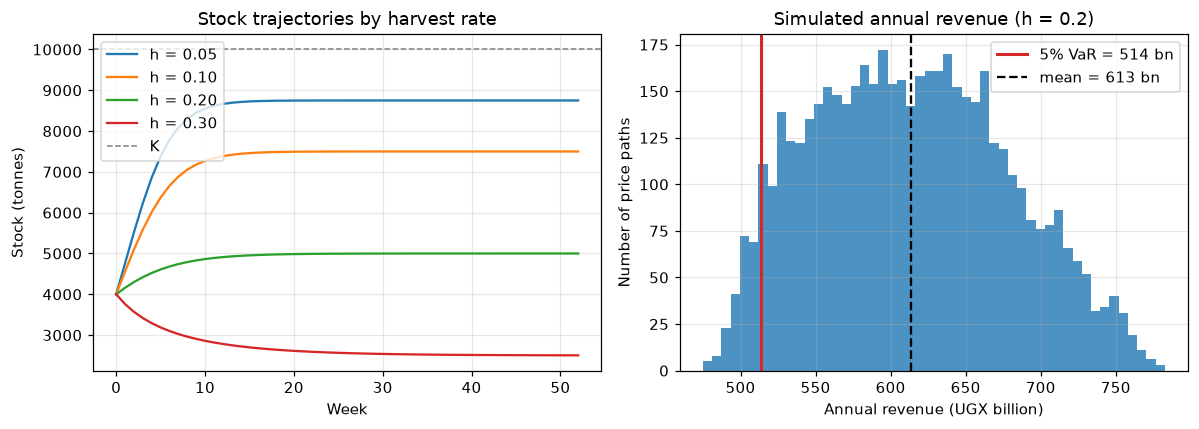

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

for h in H_SCENARIOS:
    ax[0].plot(results[h]["stock"], label=f"h = {h:.2f}")
ax[0].axhline(K, ls="--", c="grey", lw=1, label="K")
ax[0].set(title="Stock trajectories by harvest rate", xlabel="Week", ylabel="Stock (tonnes)")
ax[0].legend()

rev = results[H_FOCUS]["total_revenue"] / 1e9
var5 = results[H_FOCUS]["var_quantile"] / 1e9
ax[1].hist(rev, bins=50, color="C0", alpha=0.8)
ax[1].axvline(var5, c="C3", lw=2, label=f"5% VaR = {var5:,.0f} bn")
ax[1].axvline(rev.mean(), c="k", ls="--", label=f"mean = {rev.mean():,.0f} bn")
ax[1].set(title=f"Simulated annual revenue (h = {H_FOCUS})",
          xlabel="Annual revenue (UGX billion)", ylabel="Number of price paths")
ax[1].legend()
plt.tight_layout(); plt.show()

## Extension. Closed season (8 weeks per year, 5 years)

Fishing is closed for weeks 1-8 of every 52-week year (the closure window is a parameter: `start_week`). The stock still grows during closed weeks. Revenue is compared over 260 weeks with and without closure, using the same price seed so the comparison is fair.

,"5-yr revenue, open (UGX bn)","5-yr revenue, closed (UGX bn)",change (%),final stock open (t),final stock closed (t)
h,,,,,
0.05,"1,384.10","1,191.42",-13.92,"8,750.00","8,750.00"
0.10,"2,374.39","2,067.29",-12.93,"7,500.00","7,500.00"
0.20,"3,178.51","2,895.06",-8.92,"5,000.00","5,000.11"
0.30,"2,435.73","2,582.19",6.01,"2,500.00","2,515.13"


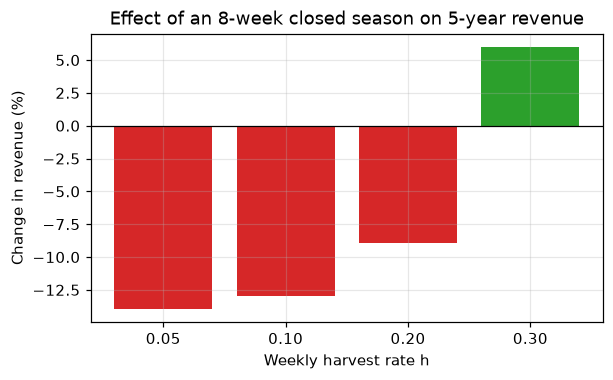

In [9]:
WEEKS_5Y = 260
mask = closed_season_mask(WEEKS_5Y, closed_weeks=8, start_week=0)
ext_rows = []
for h in H_SCENARIOS:
    open_ = run_scenario(fish, h, PriceModel(seed=SEED + 2), assessor, WEEKS_5Y, 2_000)
    closed = run_scenario(fish, h, PriceModel(seed=SEED + 2), assessor, WEEKS_5Y, 2_000, closed=mask)
    ext_rows.append({
        "h": h,
        "5-yr revenue, open (UGX bn)": open_["mean"] / 1e9,
        "5-yr revenue, closed (UGX bn)": closed["mean"] / 1e9,
        "change (%)": 100 * (closed["mean"] / open_["mean"] - 1),
        "final stock open (t)": open_["stock"][-1],
        "final stock closed (t)": closed["stock"][-1],
    })
ext = pd.DataFrame(ext_rows).set_index("h")
display(ext)

fig, ax = plt.subplots(figsize=(6, 3.4))
colors = ["C3" if v < 0 else "C2" for v in ext["change (%)"]]
ax.bar([f"{h:.2f}" for h in ext.index], ext["change (%)"], color=colors)
ax.axhline(0, c="k", lw=0.8)
ax.set(title="Effect of an 8-week closed season on 5-year revenue",
       xlabel="Weekly harvest rate h", ylabel="Change in revenue (%)")
plt.show()

## Findings & Limitations

**Sustainability.** Every tested rate keeps the stock alive (all h < r = 0.4), converging to N* = K(1 − h/r): 8,750, 7,500, 5,000 and 2,500 t. But surviving is not the same as being well managed. Yield peaks at h = r/2 = 0.20, where first-year harvest is already 98% of annual MSY (52,000 t). At h = 0.30 the cooperative lands about 17% less fish and revenue than at 0.20 while holding half the stock, so it works harder for less and has a thinner buffer against a bad year. Rates below 0.20 protect the stock but leave income on the table.

**Risk.** Annual-revenue CV is about 0.10–0.11 in every scenario, so all are classed Low. This is expected: harvest is deterministic here, so relative revenue risk simply mirrors price risk. The harvest rate changes the *level* of revenue, not its relative volatility; the 5% VaR rises from UGX 218 bn at h = 0.05 to 514 bn at h = 0.20. CV alone therefore cannot rank the scenarios, and stock status and VaR must be read with it. The closed season cuts five-year revenue by 9–14% for h ≤ 0.20 but raises it by about 6% at h = 0.30, so closures pay only when fishing is beyond MSY.

**Limitations.** Stock dynamics are deterministic (no environmental shocks, recruitment noise or illegal fishing). Price is independent of catch and of the stock. Harvest proportional to stock ignores effort, costs and catchability, so revenue is not profit. r, K and the price volatility are illustrative, and a weekly r of 0.4 is fast for real fish. CV cut-offs are rules of thumb, and results sit close to the 0.10–0.15 range, so a different price volatility would change the classes.